# 05 · Decision trees and random forests

**Decision tree:** recursively split the data on one feature/threshold at a time, choosing the split that most reduces error (MSE for regression, Gini/entropy for classification). Each leaf predicts the average of its training rows.
- Handles non-linearity and interactions automatically, needs no scaling, robust to outliers in $x$.
- A single deep tree **overfits badly** (high variance).

**Random forest:** average many deep trees, each trained on a bootstrap sample and considering only a random subset of features at each split (`max_features`). Averaging decorrelated trees cuts variance, so it's hard to overfit by adding trees.

| Param | Role |
|---|---|
| `n_estimators` | more is better (diminishing returns); 300–1000 typical |
| `max_features` | features tried per split: lower = more diverse trees. Regression default 1.0 (all); try 0.3–0.5 |
| `min_samples_leaf` | smooths leaves; 1–5 typical |
| `max_depth` | usually leave `None` for RF |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error as rmse

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

## 1. A single tree: depth controls bias vs variance

best single tree: depth 9, test RMSE 0.644


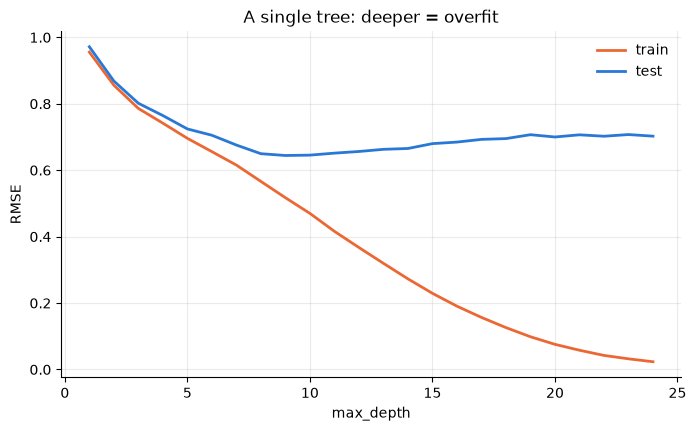

In [3]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

depths = range(1, 25)
tr, te = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train)
    tr.append(rmse(y_train, t.predict(X_train))); te.append(rmse(y_test, t.predict(X_test)))

fig, ax = plt.subplots()
ax.plot(depths, tr, label="train", color=PALETTE[1]); ax.plot(depths, te, label="test", color=PALETTE[0])
ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE"); ax.legend(); ax.set_title("A single tree: deeper = overfit")
print(f"best single tree: depth {depths[int(np.argmin(te))]}, test RMSE {min(te):.3f}")
plt.show()

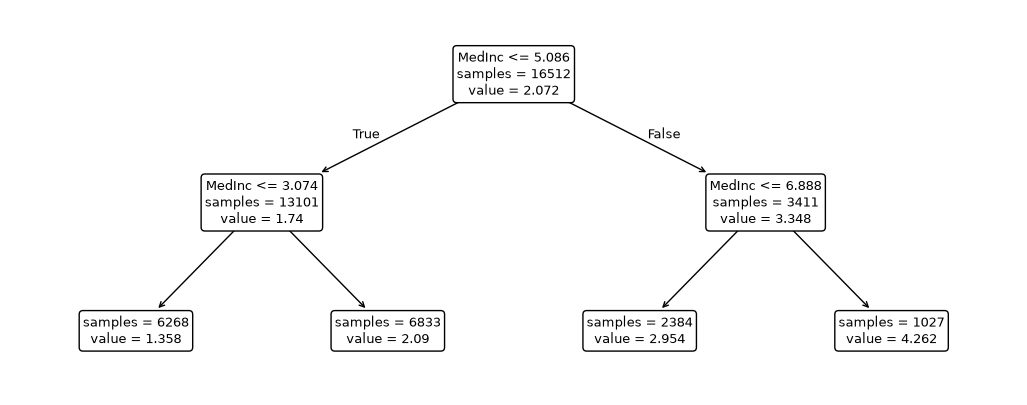

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(DecisionTreeRegressor(max_depth=2).fit(X_train, y_train), feature_names=list(X.columns),
          filled=False, rounded=True, fontsize=9, ax=ax, impurity=False)
plt.show()

## 2. Random forest
`oob_score=True` evaluates each tree on the ~37% of rows left out of its bootstrap sample, which gives you a free validation score.

In [5]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

rf = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, oob_score=True, n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
print(f"RF  OOB R²: {rf.oob_score_:.3f} | test RMSE: {rmse(y_test, rf.predict(X_test)):.3f}")

et = ExtraTreesRegressor(n_estimators=300, max_features=0.7, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(X_train, y_train)
print(f"ExtraTrees test RMSE: {rmse(y_test, et.predict(X_test)):.3f}  (random thresholds, even more variance reduction)")

RF  OOB R²: 0.819 | test RMSE: 0.496


ExtraTrees test RMSE: 0.498  (random thresholds, even more variance reduction)


More trees never hurt accuracy, but they stop helping. The test error flattens out:

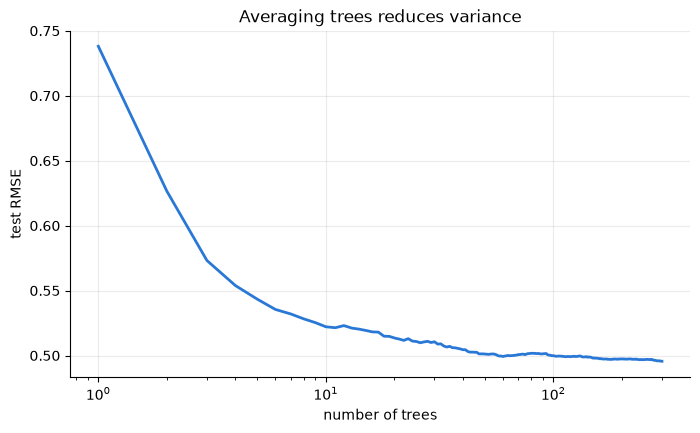

In [6]:
all_preds = np.stack([t.predict(X_test.values) for t in rf.estimators_])
n_trees = np.arange(1, len(rf.estimators_) + 1)
running = np.cumsum(all_preds, axis=0) / n_trees[:, None]
curve = [rmse(y_test, running[i]) for i in range(len(n_trees))]

fig, ax = plt.subplots()
ax.plot(n_trees, curve, color=PALETTE[0])
ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_ylabel("test RMSE"); ax.set_title("Averaging trees reduces variance")
plt.show()

## 3. Feature importance — careful

`feature_importances_` (impurity-based) is computed on *training* data and is **biased toward high-cardinality / continuous features**, even pure noise.
**Permutation importance** on held-out data asks the right question: how much does the score drop if this column is shuffled?

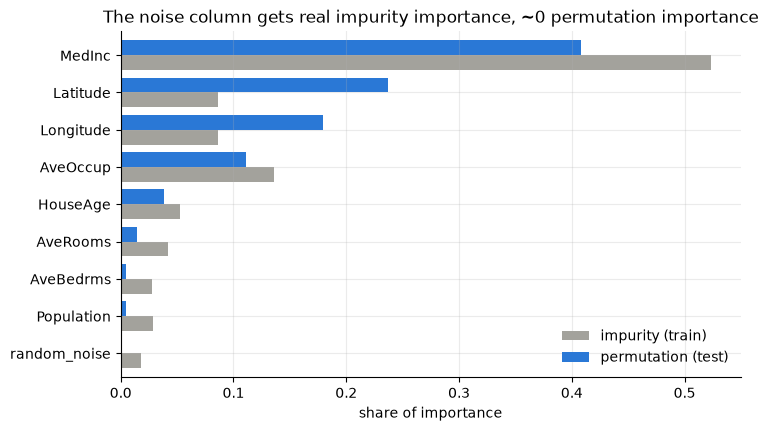

In [7]:
from sklearn.inspection import permutation_importance

X_train_n = X_train.assign(random_noise=rng.normal(size=len(X_train)))
X_test_n = X_test.assign(random_noise=rng.normal(size=len(X_test)))
rf_n = RandomForestRegressor(n_estimators=200, min_samples_leaf=1, n_jobs=-1, random_state=SEED).fit(X_train_n, y_train)

imp = pd.DataFrame({
    "impurity (train)": rf_n.feature_importances_,
    "permutation (test)": permutation_importance(rf_n, X_test_n, y_test, n_repeats=5, random_state=SEED, n_jobs=-1).importances_mean,
}, index=X_train_n.columns)
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
imp.sort_values("permutation (test)").plot.barh(ax=ax, color=[GREY, PALETTE[0]], width=0.8)
ax.set_xlabel("share of importance"); ax.set_title("The noise column gets real impurity importance, ~0 permutation importance")
plt.show()

## 4. Trees can't extrapolate

A tree predicts averages of training targets, so outside the training range its prediction is flat. A linear model follows the trend.
Important for anything with trends (prices over time, growth): de-trend, use differences/ratios as targets, or use a linear model.

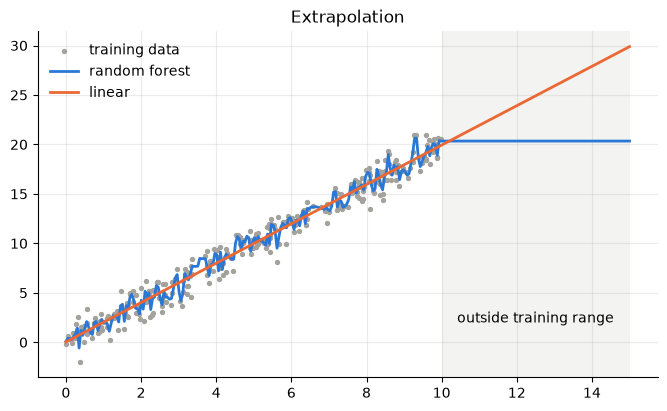

In [8]:
from sklearn.linear_model import LinearRegression

x_tr = rng.uniform(0, 10, 300); y_tr = 2 * x_tr + rng.normal(size=300)
x_grid = np.linspace(0, 15, 300)
fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, s=8, color=GREY, label="training data")
ax.plot(x_grid, RandomForestRegressor(200, random_state=SEED).fit(x_tr[:, None], y_tr).predict(x_grid[:, None]), color=PALETTE[0], label="random forest")
ax.plot(x_grid, LinearRegression().fit(x_tr[:, None], y_tr).predict(x_grid[:, None]), color=PALETTE[1], label="linear")
ax.axvspan(10, 15, color=GREY, alpha=0.12, lw=0); ax.text(12.5, 2, "outside training range", ha="center")
ax.legend(); ax.set_title("Extrapolation")
plt.show()

## Takeaways
- Single trees: interpretable, but weak. Use them to *explain*, not to *predict*.
- Random forest: strong default with almost no tuning, free OOB validation, hard to break. Usually beaten by tuned gradient boosting (next notebooks), but more robust out of the box.
- Use **permutation importance** (or SHAP, notebook 12), not impurity importance.
- Trees don't extrapolate; engineer the target/features accordingly.